# 标普500 内部 63 日动量因子的 20 日预测有效性

本 notebook 检验一个具体问题: 对当前数据库内的 S&P 500 成员, 过去约一个季度涨得更多的股票, 在接下来约一个月是否继续涨得更多

## 计算口径

- 因子: $MOM_{63,t}=\ln(P_t/P_{t-63})$, 即 63 个交易日的累计对数收益, 对应 base_momfactor(window=63, skip=0)
- 行业中性因子: 每个交易日按 sub_industry 减去同行业均值, 对应 neutralize_by_industry
- 标签: $R_t^{(20)}=P_{t+21}/P_{t+1}-1$, 即 $t+1$ 日收盘入场, $t+21$ 日收盘出场, 对应 future_returns(n_periods=20, gap=1)
- 样本: DuckDB prices 表中的 adj_close, 股票池是数据库 universe 表当前的 503 只 S&P 500 成员

## 分析步骤

1. 数据读取与时间对齐
2. 样本覆盖: 哪些股票能算出因子和标签
3. 原始动量与行业中性动量的每日 IC 与 Rank IC
4. IC 均值, 标准差, ICIR, IC 大于 0 的比例
5. 重叠标签的自相关诊断与 Newey-West 推断
6. 滞后阶数, 非重叠抽样, 分段样本等稳健性检验
7. 分位组合的 20 日平均收益

## 1 数据读取与时间对齐

prices 以 (date, ticker) 为主键, 入库时已补齐每只股票首尾之间的交易日缺口
补齐日的价格沿用前一条记录, volume = 0
这里只取 adj_close, 它是同一复权口径下的收盘价

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from loguru import logger

from quanttoolkit.db.connection import DB, get_duckdb
from quanttoolkit.factors.mom_base import base_momfactor
from quanttoolkit.factors.neutral import neutralize_by_industry
from quanttoolkit.metrics import ic, ic_summary, rank_ic
from quanttoolkit.panel.returns import future_returns

logger.remove()
logger.add(sys.stderr, level="WARNING")

plt.rcParams.update(
    {
        "figure.dpi": 120,
        "savefig.dpi": 200,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

FIG_DIR = Path("figures")
OUT_DIR = Path("outputs")
FIG_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)
print(DB)

/Users/liu/quant/QuantToolKit/data/quanttoolkit.db


In [2]:
with get_duckdb(path=DB) as connection:
    universe = connection.execute(
        "SELECT ticker, name, sub_industry FROM universe ORDER BY ticker"
    ).df()
    prices = connection.execute(
        "SELECT date, ticker, adj_close, volume FROM prices ORDER BY date, ticker"
    ).df()

industry = universe.set_index("ticker")["sub_industry"]
prices = prices.set_index(["date", "ticker"]).sort_index()

print("成员数", len(universe), "子行业数", industry.nunique())
print(
    "行情行数", len(prices), "股票数", prices.index.get_level_values("ticker").nunique()
)
print(
    "日期范围",
    prices.index.get_level_values("date").min().date(),
    "至",
    prices.index.get_level_values("date").max().date(),
)
print("交易日数", prices.index.get_level_values("date").nunique())
print("adj_close 缺失", prices["adj_close"].isna().sum())
print("成交量为 0 的补齐日", (prices["volume"] == 0).sum())
display(prices.head())

成员数 503 子行业数 126
行情行数 1315667 股票数 503
日期范围 2016-01-04 至 2026-10-09
交易日数 2708
adj_close 缺失 0
成交量为 0 的补齐日 2743


adj_close       volume
date       ticker                        
2016-01-04 A       37.356041    3287300.0
           AAPL    23.688675  270597600.0
           ABBV    37.132965   10308400.0
           ABT     34.910652   12227500.0
           ACGL    21.823122    1220700.0

## 2 因子与标签

动量在 $t$ 日收盘后得到, 只使用 $t-63$ 到 $t$ 的价格
标签从 $t+1$ 日收盘开始, 到 $t+21$ 日收盘结束, 因此标签使用的 20 个日收益与因子窗口不重叠
因子在 $t$ 日有效需要 64 条价格记录, 标签在 $t$ 日有效还需要之后 21 条记录

In [3]:
mom = base_momfactor(prices=prices, window=63)
target = future_returns(df=prices, n_periods=20, gap=1)
mom_neutral = neutralize_by_industry(mom.to_frame(), industry)["mom_63"]

panel = pd.concat(
    {"mom": mom, "mom_neutral": mom_neutral, "target": target},
    axis=1,
)
sample = panel.dropna()

print("mom_63 首个有效日", mom.first_valid_index()[0].date())
print("标签首个有效日", target.first_valid_index()[0].date())
print("完整样本行数", len(sample))
print(
    "完整样本日期范围",
    sample.index.get_level_values("date").min().date(),
    "至",
    sample.index.get_level_values("date").max().date(),
)
display(panel.head())

mom_63 首个有效日 2016-04-05
标签首个有效日 2016-01-04
完整样本行数 1273494
完整样本日期范围 2016-04-05 至 2026-09-10


mom  mom_neutral    target
date       ticker                            
2016-01-04 A       NaN          NaN -0.082861
           AAPL    NaN          NaN -0.061922
           ABBV    NaN          NaN  0.001168
           ABT     NaN          NaN -0.108575
           ACGL    NaN          NaN -0.036324

## 3 样本覆盖: 哪些股票能被识别

universe 是最近一次抓取的当前成员名单, 不是历史成分股名单
所以样本回答的是"当前 503 只成员在 2016 年以来的表现", 存在幸存者偏差
这里把"能被动量因子识别"定义为: 该股票在某个交易日同时有有效的 $MOM_{63}$ 和已实现的 20 日标签

In [4]:
price_dates = prices.index.get_level_values("date")
price_tickers = prices.index.get_level_values("ticker")


def first_valid_date(series):
    valid = series.dropna()
    return (
        pd.Series(
            valid.index.get_level_values("date"),
            index=valid.index.get_level_values("ticker"),
        )
        .groupby(level=0)
        .min()
    )


coverage = pd.DataFrame(index=pd.Index(universe["ticker"], name="ticker"))
coverage["name"] = universe.set_index("ticker")["name"]
coverage["sub_industry"] = industry
coverage["n_prices"] = prices.groupby(level="ticker").size()
coverage["first_price"] = (
    pd.Series(price_dates, index=price_tickers).groupby(level=0).min()
)
coverage["last_price"] = (
    pd.Series(price_dates, index=price_tickers).groupby(level=0).max()
)
coverage["first_factor"] = first_valid_date(mom)
coverage["first_sample"] = first_valid_date(sample["mom"])
coverage["n_valid"] = (
    sample.groupby(level="ticker").size().reindex(coverage.index, fill_value=0)
)

daily_n = sample.groupby(level="date").size()

n_all = len(coverage)
n_price = int(coverage["n_prices"].gt(0).sum())
n_factor = int(coverage["first_factor"].notna().sum())
n_sample = int(coverage["first_sample"].notna().sum())

print(
    f"当前成员 {n_all}, 有价格 {n_price}, 至少一天有因子 {n_factor}, 至少一天有因子和标签 {n_sample}"
)
print(
    f"每日截面: 均值 {daily_n.mean():.1f}, 最小 {daily_n.min()}, 最大 {daily_n.max()}, 交易日 {len(daily_n)}"
)
print(
    f"首日截面 {daily_n.index[0].date()} 有 {daily_n.iloc[0]} 只, 末日截面 {daily_n.index[-1].date()} 有 {daily_n.iloc[-1]} 只"
)
print("没有任何完整样本的股票")
display(
    coverage[coverage["first_sample"].isna()][
        ["name", "sub_industry", "n_prices", "first_price", "first_factor"]
    ]
)

当前成员 503, 有价格 503, 至少一天有因子 502, 至少一天有因子和标签 501
每日截面: 均值 485.3, 最小 464, 最大 501, 交易日 2624
首日截面 2016-04-05 有 464 只, 末日截面 2026-09-10 有 501 只
没有任何完整样本的股票


,name,sub_industry,n_prices,first_price,first_factor
ticker,,,,,
HONA,Honeywell Aerospace,Aerospace & Defense,82,2026-06-15,2026-09-15
VYLR,Vylor,Agricultural Products & Services,7,2026-10-01,NaT


In [5]:
late = coverage[coverage["first_price"] > pd.Timestamp("2016-01-04")].sort_values(
    "first_price"
)
late_display = late[
    [
        "name",
        "sub_industry",
        "n_prices",
        "first_price",
        "first_factor",
        "first_sample",
        "n_valid",
    ]
].copy()
for col in ["first_price", "first_factor", "first_sample"]:
    late_display[col] = late_display[col].dt.date
print("晚上市股票数", len(late))
display(late_display)
late_display.to_csv(OUT_DIR / "late_listings.csv")
coverage.to_csv(OUT_DIR / "coverage_by_ticker.csv")

晚上市股票数 39


,name,sub_industry,n_prices,first_price,first_factor,first_sample,n_valid
ticker,,,,,,,
TWLO,Twilio,Systems Software,2589,2016-06-23,2016-09-22,2016-09-22,2505
FTV,Fortive,Industrial Machinery & Supplies & Components,2582,2016-07-05,2016-10-03,2016-10-03,2498
DELL,Dell Technologies,"Technology Hardware, Storage & Peripherals",2551,2016-08-17,2016-11-15,2016-11-15,2467
VST,Vistra Corp.,Electric Utilities,2517,2016-10-05,2017-01-05,2017-01-05,2433
HWM,Howmet Aerospace,Aerospace & Defense,2498,2016-11-01,2017-02-02,2017-02-02,2414
INVH,Invitation Homes,Single-Family Residential REITs,2436,2017-02-01,2017-05-03,2017-05-03,2352
CVNA,Carvana,Automotive Retail,2376,2017-04-28,2017-07-28,2017-07-28,2292
IR,Ingersoll Rand,Industrial Machinery & Supplies & Components,2366,2017-05-12,2017-08-11,2017-08-11,2282
VICI,Vici Properties,Hotel & Resort REITs,2205,2018-01-02,2018-04-04,2018-04-04,2121


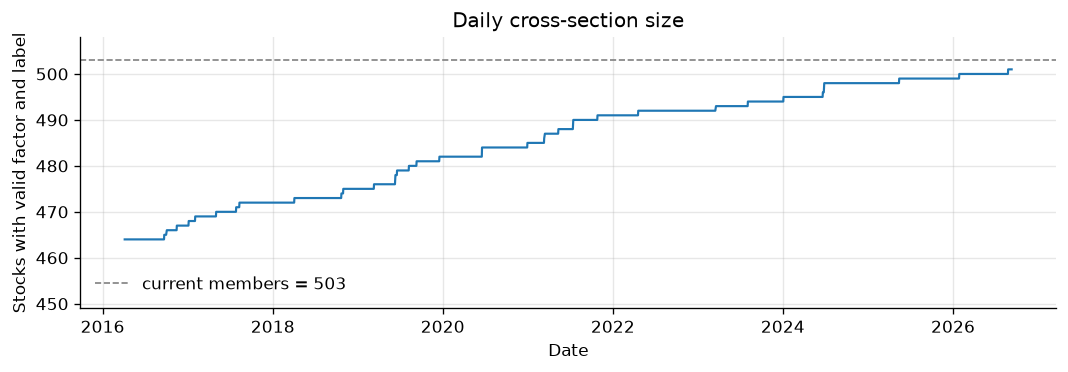

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(daily_n.index, daily_n.values, lw=1.3, color="C0")
ax.axhline(n_all, color="gray", ls="--", lw=1, label=f"current members = {n_all}")
ax.set_ylim(daily_n.min() - 15, n_all + 5)
ax.set_xlabel("Date")
ax.set_ylabel("Stocks with valid factor and label")
ax.set_title("Daily cross-section size")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_coverage.png", bbox_inches="tight")
plt.show()

## 4 每日 IC 与 Rank IC

每个交易日 $t$ 在当日有完整因子和标签的股票上计算截面相关

$$IC_t=\operatorname{corr}_i\left(MOM_{63,i,t},R_{i,t}^{(20)}\right),\qquad
RankIC_t=\operatorname{corr}_i\left(\operatorname{rank}(MOM_{63,i,t}),\operatorname{rank}(R_{i,t}^{(20)})\right)$$

原始动量和行业中性动量分别计算 Pearson IC 与 Spearman Rank IC

In [7]:
daily_ic = pd.DataFrame(
    {
        "ic_raw": ic(factor=sample["mom"], forward_return=sample["target"]),
        "ic_neutral": ic(factor=sample["mom_neutral"], forward_return=sample["target"]),
        "rank_ic_raw": rank_ic(factor=sample["mom"], forward_return=sample["target"]),
        "rank_ic_neutral": rank_ic(
            factor=sample["mom_neutral"], forward_return=sample["target"]
        ),
    }
)
daily_ic.index.name = "date"
print("IC 序列形状", daily_ic.shape, "缺失值", int(daily_ic.isna().sum().sum()))
display(daily_ic.head())
display(daily_ic.describe().T)
daily_ic.to_csv(OUT_DIR / "daily_ic.csv")

IC 序列形状 (2624, 4) 缺失值 0


,ic_raw,ic_neutral,rank_ic_raw,rank_ic_neutral
date,,,,
2016-04-05,-0.015338,-0.035086,-0.071444,-0.056433
2016-04-06,-0.082900,-0.063033,-0.129558,-0.063978
2016-04-07,-0.038089,-0.035480,-0.126553,-0.048003
2016-04-08,-0.055183,-0.017994,-0.151091,-0.055976
2016-04-11,-0.077618,-0.045148,-0.154638,-0.066844


,count,mean,std,min,25%,50%,75%,max
ic_raw,2624.0,-0.005623,0.200567,-0.796678,-0.121714,0.014994,0.136441,0.544945
ic_neutral,2624.0,0.001180,0.132758,-0.521497,-0.068676,0.011108,0.092126,0.324788
rank_ic_raw,2624.0,-0.013300,0.185854,-0.725823,-0.120807,0.002656,0.114693,0.541751
rank_ic_neutral,2624.0,-0.005653,0.088948,-0.313501,-0.056077,-0.001041,0.057714,0.228097


## 5 IC 汇总与 ICIR

$ICIR=\overline{IC}/s(IC)$, 使用 ddof=1 的样本标准差, 不做年化
$IC>0$ 比例是有效交易日里 IC 严格大于 0 的比例

In [8]:
ic_table = pd.DataFrame({col: ic_summary(ic=daily_ic[col]) for col in daily_ic}).T
ic_table.insert(0, "n_days", daily_ic.notna().sum())
ic_table["se_naive"] = ic_table["ic_std"] / np.sqrt(ic_table["n_days"])
ic_table["t_naive"] = ic_table["ic_mean"] / ic_table["se_naive"]
display(ic_table.round(6))
ic_table.to_csv(OUT_DIR / "ic_summary.csv")

,n_days,ic_mean,ic_std,ic_ir,ic_pos,se_naive,t_naive
ic_raw,2624,-0.005623,0.200567,-0.028034,0.536585,0.003915,-1.436039
ic_neutral,2624,0.001180,0.132758,0.008890,0.541921,0.002592,0.455371
rank_ic_raw,2624,-0.013300,0.185854,-0.071564,0.507622,0.003628,-3.665877
rank_ic_neutral,2624,-0.005653,0.088948,-0.063559,0.495046,0.001736,-3.255800


## 6 重叠标签与 Newey-West

$t$ 日与 $t+1$ 日的 20 日标签共享 19 个日收益, 每日 IC 序列因此高度自相关
若不处理, 均值的朴素标准误 $s/\sqrt{T}$ 会被严重低估
对 $IC_t=\mu+\varepsilon_t$ 用 HAC 协方差, Bartlett 核最大滞后 20 期, 得到 $\mu$ 的 Newey-West 标准误
用 Bartlett 权重下的自相关和估计有效样本量

$$T_{\text{eff}}=\frac{T}{1+2\sum_{k=1}^{L}\left(1-\frac{k}{L+1}\right)\rho_k}$$

In [9]:
lags = [1, 2, 3, 5, 10, 15, 20, 30, 40, 60]
acf = pd.DataFrame(
    {col: [daily_ic[col].autocorr(lag) for lag in lags] for col in daily_ic},
    index=lags,
)
acf.index.name = "lag"


def effective_sample(series, maxlags=20):
    values = series.dropna()
    weights = np.array([1 - k / (maxlags + 1) for k in range(1, maxlags + 1)])
    rhos = np.array([values.autocorr(k) for k in range(1, maxlags + 1)])
    return len(values) / (1 + 2 * np.sum(weights * rhos))


n_eff = pd.Series(
    {col: effective_sample(daily_ic[col]) for col in daily_ic}, name="n_eff"
)
display(acf.round(3))
display(n_eff.round(1).to_frame())
acf.to_csv(OUT_DIR / "ic_acf.csv")

,ic_raw,ic_neutral,rank_ic_raw,rank_ic_neutral
lag,,,,
1,0.928,0.939,0.919,0.924
2,0.853,0.874,0.835,0.843
3,0.786,0.816,0.758,0.767
5,0.671,0.718,0.623,0.641
10,0.427,0.500,0.342,0.380
15,0.174,0.256,0.071,0.112
20,-0.061,0.016,-0.154,-0.127
30,-0.078,-0.067,-0.085,-0.066
40,-0.040,-0.018,-0.051,0.011


,n_eff
ic_raw,212.8
ic_neutral,195.9
rank_ic_raw,235.8
rank_ic_neutral,225.6


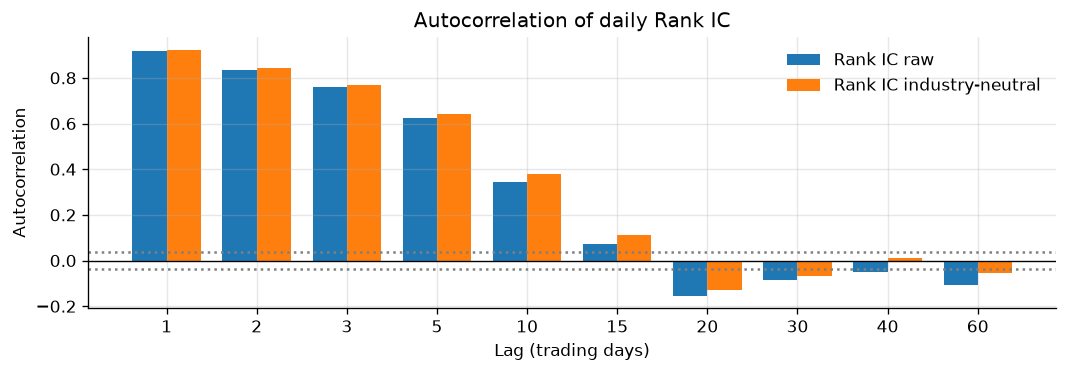

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.2))
positions = np.arange(len(lags))
width = 0.38
ax.bar(positions - width / 2, acf["rank_ic_raw"], width=width, label="Rank IC raw")
ax.bar(
    positions + width / 2,
    acf["rank_ic_neutral"],
    width=width,
    label="Rank IC industry-neutral",
)
ax.axhline(0, color="black", lw=0.8)
band = 1.96 / np.sqrt(len(daily_ic))
ax.axhline(band, color="gray", ls=":")
ax.axhline(-band, color="gray", ls=":")
ax.set_xticks(positions, [str(lag) for lag in lags])
ax.set_xlabel("Lag (trading days)")
ax.set_ylabel("Autocorrelation")
ax.set_title("Autocorrelation of daily Rank IC")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_acf.png", bbox_inches="tight")
plt.show()

In [11]:
def newey_west_mean(series, maxlags=20):
    values = series.dropna().to_numpy()
    result = sm.OLS(values, np.ones((len(values), 1))).fit(
        cov_type="HAC", cov_kwds={"maxlags": maxlags}, use_t=False
    )
    low, high = result.conf_int(alpha=0.05)[0]
    return pd.Series(
        {
            "n": len(values),
            "mean": result.params[0],
            "nw_se": result.bse[0],
            "z": result.tvalues[0],
            "p_value": result.pvalues[0],
            "ci_low": low,
            "ci_high": high,
        }
    )


nw = pd.DataFrame(
    {col: newey_west_mean(daily_ic[col], maxlags=20) for col in daily_ic}
).T
nw["n_eff"] = n_eff
nw["se_naive"] = daily_ic.std(ddof=1) / np.sqrt(daily_ic.notna().sum())
nw["se_ratio"] = nw["nw_se"] / nw["se_naive"]
nw["t_naive"] = nw["mean"] / nw["se_naive"]
display(nw.round(6))
nw.to_csv(OUT_DIR / "ic_newey_west.csv")

,n,mean,nw_se,z,p_value,ci_low,ci_high,n_eff,se_naive,se_ratio,t_naive
ic_raw,2624.0,-0.005623,0.013744,-0.409111,0.682459,-0.032560,0.021314,212.769383,0.003915,3.510150,-1.436039
ic_neutral,2624.0,0.001180,0.009482,0.124466,0.900947,-0.017404,0.019764,195.889043,0.002592,3.658608,0.455371
rank_ic_raw,2624.0,-0.013300,0.012099,-1.099325,0.271626,-0.037014,0.010413,235.763209,0.003628,3.334662,-3.665877
rank_ic_neutral,2624.0,-0.005653,0.005920,-0.954964,0.339596,-0.017257,0.005950,225.567313,0.001736,3.409342,-3.255800


## 7 稳健性检验

- 滞后阶数: 把 Newey-West 的最大滞后从 5 改到 120, 检查推断是否稳定
- 非重叠抽样: 每 20 个交易日取一个截面, 标签几乎不重叠, 用普通 $t$ 统计量交叉验证
- 分段样本: 按时间等分前后两段, 检查预测力的方向是否稳定
- 分年度: 观察 IC 是否集中在个别年份

In [12]:
lag_grid = [5, 10, 20, 40, 60, 120]
lag_z = pd.DataFrame(
    {
        col: {lag: newey_west_mean(daily_ic[col], maxlags=lag)["z"] for lag in lag_grid}
        for col in daily_ic
    }
)
lag_z.index.name = "maxlags"
display(lag_z.round(3))
lag_z.to_csv(OUT_DIR / "ic_newey_west_lag_sensitivity.csv")

,ic_raw,ic_neutral,rank_ic_raw,rank_ic_neutral
maxlags,,,,
5,-0.631,0.198,-1.629,-1.441
10,-0.496,0.154,-1.295,-1.139
20,-0.409,0.124,-1.099,-0.955
40,-0.384,0.114,-1.076,-0.917
60,-0.384,0.111,-1.108,-0.910
120,-0.435,0.112,-1.357,-1.007


In [13]:
non_overlap = daily_ic.iloc[::20]
non_overlap_rows = {}
for col in daily_ic:
    values = non_overlap[col].dropna()
    non_overlap_rows[col] = {
        "n": len(values),
        "mean": values.mean(),
        "z": values.mean() / (values.std(ddof=1) / np.sqrt(len(values))),
    }
non_overlap_table = pd.DataFrame(non_overlap_rows).T
print("每 20 个交易日抽样, 近似非重叠样本")
display(non_overlap_table.round(4))

half = len(daily_ic) // 2
parts = {"first": daily_ic.iloc[:half], "second": daily_ic.iloc[half:]}
print("前半段", parts["first"].index[0].date(), "至", parts["first"].index[-1].date())
print("后半段", parts["second"].index[0].date(), "至", parts["second"].index[-1].date())
sub_rows = {}
for name, part in parts.items():
    for col in daily_ic:
        stats = newey_west_mean(part[col])
        sub_rows[(name, col)] = {"mean": stats["mean"], "z": stats["z"]}
sub_table = pd.DataFrame(sub_rows).T
display(sub_table.round(4))

每 20 个交易日抽样, 近似非重叠样本


,n,mean,z
ic_raw,132.0,-0.0039,-0.2442
ic_neutral,132.0,-0.0010,-0.0922
rank_ic_raw,132.0,-0.0098,-0.6568
rank_ic_neutral,132.0,-0.0056,-0.7624


前半段 2016-04-05 至 2021-06-18
后半段 2021-06-21 至 2026-09-10


mean       z
first  ic_raw          -0.0170 -0.9301
       ic_neutral      -0.0168 -1.4587
       rank_ic_raw     -0.0101 -0.5854
       rank_ic_neutral -0.0115 -1.4912
second ic_raw           0.0058  0.2828
       ic_neutral       0.0191  1.2978
       rank_ic_raw     -0.0165 -0.9765
       rank_ic_neutral  0.0002  0.0258

In [14]:
robustness = pd.DataFrame(
    {
        "n": [
            len(daily_ic),
            int(non_overlap_table.loc["rank_ic_raw", "n"]),
            len(parts["first"]),
            len(parts["second"]),
        ],
        "rank_ic_raw": [
            nw.loc["rank_ic_raw", "mean"],
            non_overlap_table.loc["rank_ic_raw", "mean"],
            sub_table.loc[("first", "rank_ic_raw"), "mean"],
            sub_table.loc[("second", "rank_ic_raw"), "mean"],
        ],
        "rank_ic_raw_z": [
            nw.loc["rank_ic_raw", "z"],
            non_overlap_table.loc["rank_ic_raw", "z"],
            sub_table.loc[("first", "rank_ic_raw"), "z"],
            sub_table.loc[("second", "rank_ic_raw"), "z"],
        ],
        "rank_ic_neutral": [
            nw.loc["rank_ic_neutral", "mean"],
            non_overlap_table.loc["rank_ic_neutral", "mean"],
            sub_table.loc[("first", "rank_ic_neutral"), "mean"],
            sub_table.loc[("second", "rank_ic_neutral"), "mean"],
        ],
        "rank_ic_neutral_z": [
            nw.loc["rank_ic_neutral", "z"],
            non_overlap_table.loc["rank_ic_neutral", "z"],
            sub_table.loc[("first", "rank_ic_neutral"), "z"],
            sub_table.loc[("second", "rank_ic_neutral"), "z"],
        ],
    },
    index=[
        "全样本 NW L=20",
        "每 20 个交易日抽样",
        f"前半段 {parts['first'].index[0].date()} 至 {parts['first'].index[-1].date()}",
        f"后半段 {parts['second'].index[0].date()} 至 {parts['second'].index[-1].date()}",
    ],
)
display(robustness.round(4))
robustness.to_csv(OUT_DIR / "robustness.csv")

,n,rank_ic_raw,rank_ic_raw_z,rank_ic_neutral,rank_ic_neutral_z
全样本 NW L=20,2624,-0.0133,-1.0993,-0.0057,-0.9550
每 20 个交易日抽样,132,-0.0098,-0.6568,-0.0056,-0.7624
前半段 2016-04-05 至 2021-06-18,1312,-0.0101,-0.5854,-0.0115,-1.4912
后半段 2021-06-21 至 2026-09-10,1312,-0.0165,-0.9765,0.0002,0.0258


,n_days,ic_raw,ic_neutral,rank_ic_raw,rank_ic_neutral
year,,,,,
2016,189,-0.0257,-0.0302,-0.0352,-0.0290
2017,251,0.0195,0.0113,0.0231,0.0057
2018,251,0.0109,0.0299,-0.0102,0.0006
2019,252,-0.0673,-0.0687,-0.0313,-0.0238
2020,253,0.0008,-0.0080,0.0115,-0.0087
2021,252,-0.0345,0.0065,-0.0349,0.0081
2022,251,0.0055,0.0164,-0.0056,-0.0020
2023,250,-0.0443,-0.0366,-0.0514,-0.0229
2024,252,0.0350,0.0431,0.0232,0.0177


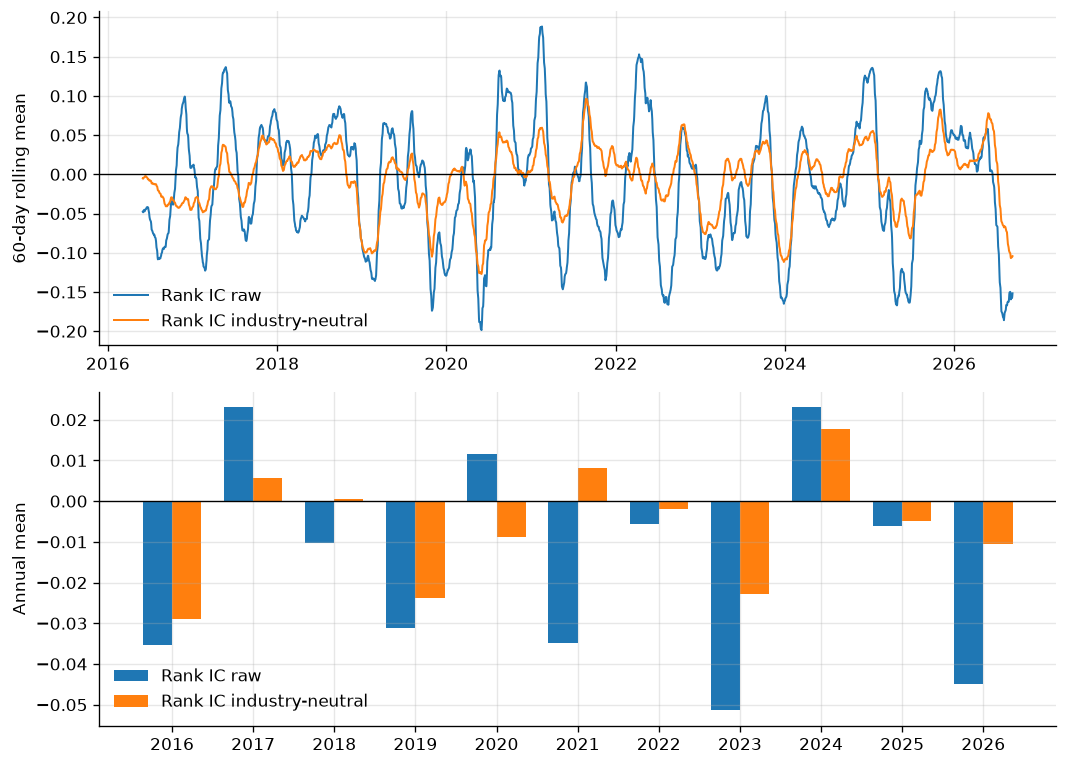

In [15]:
yearly = pd.DataFrame(
    {
        "n_days": daily_ic.groupby(daily_ic.index.year).size(),
        "ic_raw": daily_ic["ic_raw"].groupby(daily_ic.index.year).mean(),
        "ic_neutral": daily_ic["ic_neutral"].groupby(daily_ic.index.year).mean(),
        "rank_ic_raw": daily_ic["rank_ic_raw"].groupby(daily_ic.index.year).mean(),
        "rank_ic_neutral": daily_ic["rank_ic_neutral"]
        .groupby(daily_ic.index.year)
        .mean(),
    }
)
yearly.index.name = "year"
display(yearly.round(4))
yearly.to_csv(OUT_DIR / "yearly_ic.csv")

rolling = (
    daily_ic[["rank_ic_raw", "rank_ic_neutral"]].rolling(60, min_periods=40).mean()
)
fig, axes = plt.subplots(2, 1, figsize=(9, 6.5))
axes[0].plot(rolling.index, rolling["rank_ic_raw"], lw=1.2, label="Rank IC raw")
axes[0].plot(
    rolling.index, rolling["rank_ic_neutral"], lw=1.2, label="Rank IC industry-neutral"
)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_ylabel("60-day rolling mean")
axes[0].legend(frameon=False)
years = np.arange(len(yearly))
axes[1].bar(years - 0.18, yearly["rank_ic_raw"], width=0.36, label="Rank IC raw")
axes[1].bar(
    years + 0.18,
    yearly["rank_ic_neutral"],
    width=0.36,
    label="Rank IC industry-neutral",
)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_xticks(years, yearly.index.astype(str))
axes[1].set_ylabel("Annual mean")
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_ic.png", bbox_inches="tight")
plt.show()

## 8 分位组合

每个交易日按动量从低到高分成 5 组, 计算各组未来 20 日平均收益
$Q5-Q1$ 是多头高动量, 空头低动量的 20 日收益差
由于标签重叠, 价差序列仍用最大滞后 20 期的 Newey-West 标准误

In [16]:
def quintile_returns(factor, forward_return, n_groups=5):
    frame = pd.concat(
        [factor.rename("factor"), forward_return.rename("target")], axis=1
    )
    frame = frame.dropna().reset_index()
    frame["group"] = frame.groupby("date")["factor"].transform(
        lambda x: pd.qcut(x.rank(method="first"), n_groups, labels=False)
    )
    return frame.groupby(["date", "group"])["target"].mean().unstack()


q_raw = quintile_returns(sample["mom"], sample["target"])
q_neutral = quintile_returns(sample["mom_neutral"], sample["target"])
quintile_table = pd.DataFrame({"raw": q_raw.mean(), "neutral": q_neutral.mean()}) * 100
quintile_table.index = [f"Q{i + 1}" for i in range(len(quintile_table))]
display(quintile_table.round(3))
quintile_table.to_csv(OUT_DIR / "quintile_returns.csv")

spread_raw = q_raw[4] - q_raw[0]
spread_neutral = q_neutral[4] - q_neutral[0]
spread_table = pd.DataFrame(
    {"raw": newey_west_mean(spread_raw), "neutral": newey_west_mean(spread_neutral)}
).T
spread_table["mean_bps"] = spread_table["mean"] * 1e4
display(spread_table.round(4))
spread_table.to_csv(OUT_DIR / "quintile_spread.csv")

,raw,neutral
Q1,1.740,1.688
Q2,1.337,1.285
Q3,1.234,1.290
Q4,1.225,1.217
Q5,1.547,1.601


,n,mean,nw_se,z,p_value,ci_low,ci_high,mean_bps
raw,2624.0,-0.0019,0.0031,-0.6158,0.5380,-0.0081,0.0042,-19.3505
neutral,2624.0,-0.0009,0.0018,-0.4959,0.6199,-0.0043,0.0026,-8.7170


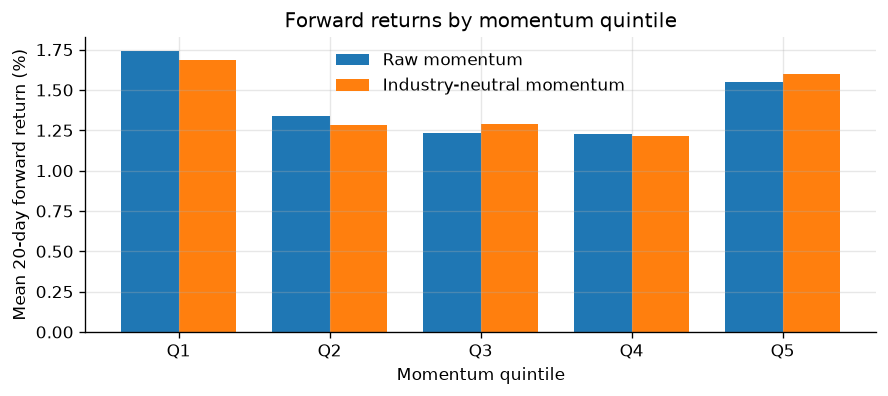

In [17]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
positions = np.arange(len(quintile_table))
width = 0.38
ax.bar(positions - width / 2, quintile_table["raw"], width=width, label="Raw momentum")
ax.bar(
    positions + width / 2,
    quintile_table["neutral"],
    width=width,
    label="Industry-neutral momentum",
)
ax.set_xticks(positions, quintile_table.index)
ax.set_xlabel("Momentum quintile")
ax.set_ylabel("Mean 20-day forward return (%)")
ax.set_title("Forward returns by momentum quintile")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_quintile.png", bbox_inches="tight")
plt.show()

## 9 结论

1. 覆盖: 当前 503 只成员都有价格, 其中 502 只可以算出至少一天的 $MOM_{63}$, 501 只可以得到至少一天的完整因子和标签, 每日截面从 464 只增加到 501 只, 平均约 485 只
2. 预测力: 原始 Rank IC 均值为负且数值很小, 行业中性化后接近 0, 四个 IC 序列的均值在统计上都无法拒绝 0
3. 重叠标签: 日度 IC 的一阶自相关约 0.92, 有效样本量只有 200 多, 朴素标准误被低估约 3.3 到 3.7 倍, 这正是 Newey-West 修正的关键
4. 稳健性: 非重叠抽样, 前后分段和分年度结果都不支持稳定的动量预测力, Newey-West 的滞后阶数从 20 改到 120 结论不变
5. 分位组合: $Q5-Q1$ 的 20 日平均价差为负且不显著, 低动量组反而略高, 与短周期反转的方向一致

综合来看, 在当前数据库的当前 S&P 500 成分股样本上, 63 日动量对 20 日未来收益没有可靠的正向预测能力
它不适合作为单独的多头选股信号, 更适合作为多因子模型中的一个候选特征再做样本外验证

## 主要局限

- 股票池是当前成员名单, 不是历史成分股, 存在幸存者偏差, 结果不能直接外推到历史 S&P 500
- 样本只覆盖 2016-04 至 2026-09 的 2624 个有效截面, 包含多次风格切换
- 市值, 成交额, 财务等控制变量未纳入, IC 是单因子截面相关
- 行业中性按 GICS 子行业, 单股票子行业中性化后恒为 0, 会轻微稀释中性因子的截面差异
- 只检验了 20 日持有期, 没有检验更长持有期和换手成本